# Zero-Shot Time-Series Forecasting on AMD GPUs

**Model:** [Timestral](https://huggingface.co/collections/mistralai/timestral) by Mistral AI, a family of time-series foundation models for **zero-shot probabilistic forecasting**.
**Hardware:** AMD Instinct MI300X GPU (ROCm). The same notebook runs CPU-only if no GPU is present.

Give the model raw history (sales, power usage, sensor readings, demand, telemetry) and it predicts what comes next, with calibrated uncertainty, **without training a model per dataset**. At launch Timestral-209M ranked #1 among pretrained / zero-shot models on GIFT-Eval, TIME, and fev-bench.

This notebook:
1. Confirms the AMD GPU is visible to PyTorch (ROCm).
2. Loads `Timestral-209M` (837 MB, downloaded once).
3. Forecasts a held-out window with 21 probability quantiles and scores it.
4. Plots the forecast with uncertainty bands.
5. Benchmarks fleet-scale batched forecasting throughput on one GPU.

> New to AMD GPUs? See the repo README for how to get **free MI300X credits** on the AMD Developer Cloud.

## 1. Install

PyTorch+ROCm is already installed in the AMD Developer Cloud ROCm image and the `rocm/pytorch` Docker image, so we only add Timestral and plotting libs. (If you are on a fresh machine, install a ROCm build of PyTorch first from https://pytorch.org.)

In [1]:
%pip install -q "git+https://github.com/mistralai/timestral.git" matplotlib pandas numpy


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Confirm the AMD GPU is visible to PyTorch

On ROCm, PyTorch exposes AMD GPUs through the same `torch.cuda` API. We also run a real matmul so this is a true capability check, not just a version string.

In [2]:
import torch, time
print("torch", torch.__version__, "| HIP", torch.version.hip)
print("GPU available:", torch.cuda.is_available(), "| count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("device:", torch.cuda.get_device_name(0))
    a = torch.randn(4096, 4096, device="cuda"); b = torch.randn(4096, 4096, device="cuda")
    torch.cuda.synchronize(); t0 = time.time()
    for _ in range(20): c = a @ b
    torch.cuda.synchronize()
    dt = (time.time() - t0) / 20
    print(f"4096^3 matmul: {dt*1000:.2f} ms  (~{2*4096**3/dt/1e12:.1f} TFLOP/s, fp32)")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

torch 2.12.0+rocm7.14.0 | HIP 7.14.60850
GPU available: True | count: 1
device: AMD Instinct MI300X VF


4096^3 matmul: 12.83 ms  (~10.7 TFLOP/s, fp32)
Using device: cuda


## 3. Load Timestral-209M

`from_pretrained` downloads `config.json` + `model.safetensors` once to the Hugging Face cache. Swap in `Timestral-5M/28M/123M` for smaller/faster variants.

In [3]:
from timestral import TimestralForecaster
import time
t0 = time.time()
forecaster = TimestralForecaster.from_pretrained("mistralai/Timestral-209M", device=DEVICE)
print(f"Loaded Timestral-209M onto {DEVICE} in {time.time()-t0:.1f}s")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded Timestral-209M onto cuda in 1.9s


## 4. Build a realistic series and forecast it

We synthesize three weeks of 15-minute electricity-load-style data (daily + weekly seasonality + trend + noise), hold out the last two days as ground truth, and let Timestral forecast them zero-shot. The context shape is `(series, variates, time)`.

In [4]:
import numpy as np
rng = np.random.default_rng(7)
spd = 96                      # 15-min steps per day
H = 21 * spd                  # 3 weeks of history
horizon = 2 * spd             # forecast 2 days ahead
tt = np.arange(H + horizon)
base = (50
        + 10*np.sin(2*np.pi*tt/spd - 1.2)      # daily cycle
        + 4*np.sin(2*np.pi*tt/(7*spd))         # weekly cycle
        + 0.004*tt)                            # slow trend
full = base + rng.normal(0, 1.5, size=tt.shape)
context, truth = full[:H], full[H:H+horizon]

ctx = context.astype(np.float32)[None, None, :]      # (1, 1, T)
forecast = forecaster.forecast(ctx, prediction_length=horizon)
print("quantiles shape:", tuple(forecast.quantiles.shape),
      "= (series, variates, horizon, 21 quantile levels)")
print("quantile levels:", tuple(round(float(q),2) for q in forecast.quantile_levels))

quantiles shape: (1, 1, 192, 21) = (series, variates, horizon, 21 quantile levels)
quantile levels: (0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99)


### Score the forecast

Mean Absolute Error of the median vs a naive "repeat the last value" baseline. Skill = how much error the model removes relative to that baseline.

In [5]:
def to_np(x):
    import torch
    return x.detach().float().cpu().numpy() if isinstance(x, torch.Tensor) else np.asarray(x)

med = to_np(forecast.median)[0, 0]
mae   = float(np.mean(np.abs(med - truth)))
naive = float(np.mean(np.abs(context[-1] - truth)))
print(f"median MAE = {mae:.2f}")
print(f"naive-last MAE = {naive:.2f}")
print(f"skill vs naive = {1 - mae/naive:.1%}")

median MAE = 1.31
naive-last MAE = 14.36
skill vs naive = 90.9%


## 5. Plot the forecast with uncertainty bands

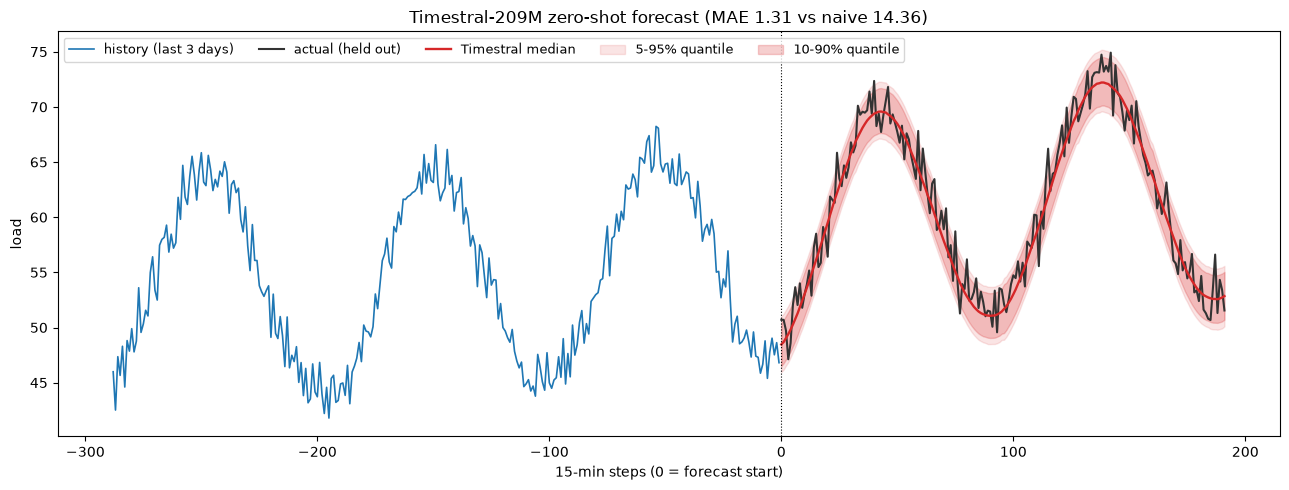

In [6]:
import matplotlib.pyplot as plt
q10, q90 = to_np(forecast.quantile(0.1))[0,0], to_np(forecast.quantile(0.9))[0,0]
q05, q95 = to_np(forecast.quantile(0.05))[0,0], to_np(forecast.quantile(0.95))[0,0]

plt.figure(figsize=(13, 5))
hx = np.arange(-3*spd, 0)
plt.plot(hx, context[hx], color="#1f77b4", lw=1.2, label="history (last 3 days)")
fx = np.arange(0, horizon)
plt.plot(fx, truth, color="#333", lw=1.5, label="actual (held out)")
plt.plot(fx, med, color="#d62728", lw=1.7, label="Timestral median")
plt.fill_between(fx, q05, q95, color="#d62728", alpha=0.12, label="5-95% quantile")
plt.fill_between(fx, q10, q90, color="#d62728", alpha=0.22, label="10-90% quantile")
plt.axvline(0, color="k", ls=":", lw=0.8)
plt.title(f"Timestral-209M zero-shot forecast (MAE {mae:.2f} vs naive {naive:.2f})")
plt.xlabel("15-min steps (0 = forecast start)"); plt.ylabel("load")
plt.legend(ncol=5, fontsize=9, loc="upper left"); plt.tight_layout()
plt.show()

## 6. Fleet-scale throughput on one AMD GPU

The real AMD Instinct story: one GPU forecasts an **entire fleet** of series in a single batched pass. Below we forecast 1 -> 1024 independent series at once and measure series/second. The 192 GB of HBM on an MI300X lets you batch a large number of series without running out of memory.

In [7]:
import time
print(f"device: {torch.cuda.get_device_name(0) if DEVICE=='cuda' else 'CPU'}")
for B in [1, 64, 256, 1024]:
    batch = (base[None, None, :H] + rng.normal(0, 1.5, size=(B, 1, H))).astype(np.float32)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    _ = forecaster.forecast(batch, prediction_length=horizon)
    if DEVICE == "cuda": torch.cuda.synchronize()
    dt = time.time() - t0
    print(f"{B:5d} series x {horizon} steps : {dt:6.2f} s = {B/dt:9.1f} series/s")

device: AMD Instinct MI300X VF
    1 series x 192 steps :   0.04 s =      26.4 series/s
   64 series x 192 steps :   0.15 s =     424.1 series/s


  256 series x 192 steps :   0.24 s =    1054.0 series/s


 1024 series x 192 steps :   1.22 s =     836.0 series/s


## Next steps

- **Use your own data:** replace `context` with a real `(series, variates, time)` array. NaN marks missing values.
- **Covariates:** pass `past_covariates` / `known_covariates` (e.g. calendar, temperature) to `forecast(...)`. See the [Timestral README](https://github.com/mistralai/timestral).
- **Public benchmarks:** GIFT-Eval, TIME, fev-bench.
- **Smaller/faster:** `Timestral-5M` forecasts in ~10 ms on CPU, great for edge deployment on AMD EPYC.

Built and verified on an **AMD Instinct MI300X** via the [AMD Developer Cloud](https://devcloud.amd.com/).